# Ejercicio para entregar — Optimización: disco de acreción con el método del gradiente

**Fuente:** `Optimizacion.pdf, secciones *Ejercicio: Maximizar la
luminosidad de un disco de acreción simplificado* y *Ejercicio para entregar* (método del gradiente).

$$L(r,\theta) = r^2 \sin\theta\,(1 + \cos\theta)\,e^{-r/r_0}, \qquad r_0 = 1$$

Restricciones físicas: $r > 0$ (numéricamente $r \in [0.1,\ 5r_0]$) y $\theta \in [0, \pi/2]$.

Valores iniciales pedidos: **a)** $(r_0, \pi/6)$, **b)** $(3r_0, \pi/4)$, **c)** $(0.5r_0, \pi/3)$.

## Gradiente analítico

$$\frac{\partial L}{\partial r} = r\,\sin\theta\,(1+\cos\theta)\,(2 - r)\,e^{-r} \qquad\qquad
\frac{\partial L}{\partial \theta} = r^2 e^{-r}\left(\cos\theta + \cos 2\theta\right)$$

(usando $\frac{d}{d\theta}[\sin\theta(1+\cos\theta)] = \cos\theta + \cos 2\theta$).

## Óptimo analítico (para verificar)

- $\partial L/\partial\theta = 0 \Rightarrow 2\cos^2\theta + \cos\theta - 1 = 0 \Rightarrow \cos\theta = 1/2 \Rightarrow \theta^* = \pi/3$ (60°)
- $\partial L/\partial r = 0 \Rightarrow r^* = 2$
- $L_{max} = 4\cdot\frac{\sqrt 3}{2}\cdot\frac{3}{2}\,e^{-2} = 3\sqrt{3}\,e^{-2} \approx 0.70324$

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

def L(r, th):
    return r**2*np.sin(th)*(1 + np.cos(th))*np.exp(-r)

def grad_L(r, th):
    dL_dr  = r*np.sin(th)*(1 + np.cos(th))*(2.0 - r)*np.exp(-r)
    dL_dth = r**2*np.exp(-r)*(np.cos(th) + np.cos(2*th))
    return dL_dr, dL_dth

def ascenso_gradiente(r0, th0, alfa0=0.05, tol=1e-8, itmax=200000):
    # ascenso del gradiente; si L no sube con el paso, lo reduzco.
    # ojo: mantengo (r, θ) dentro del dominio físico
    r, th = float(r0), float(th0)
    camino = [(r, th)]
    for k in range(1, itmax + 1):
        gr, gt = grad_L(r, th)
        if abs(gr) < tol and abs(gt) < tol:
            break
        alfa = alfa0
        while alfa > 1e-16:
            r_n  = min(max(r  + alfa*gr, 0.1), 5.0)
            th_n = min(max(th + alfa*gt, 0.0), np.pi/2)
            if L(r_n, th_n) > L(r, th):
                break
            alfa *= 0.5
        r, th = r_n, th_n
        camino.append((r, th))
    return (r, th), k, np.array(camino)

r_ex, th_ex = 2.0, np.pi/3
L_ex = L(r_ex, th_ex)

print(f"{'inicio (r, θ)':>22} {'r*':>10} {'θ* [rad]':>10} {'θ* [°]':>8} {'L(r*,θ*)':>10} {'iters':>7} {'|∇L| final':>11}")
print("-" * 84)
resultados = {}
for etiqueta, (r0, th0) in {'a': (1.0, np.pi/6), 'b': (3.0, np.pi/4), 'c': (0.5, np.pi/3)}.items():
    (rs, ths), k, camino = ascenso_gradiente(r0, th0)
    resultados[etiqueta] = camino
    gr, gt = grad_L(rs, ths)
    print(f"({r0:.1f}, {np.degrees(th0):.1f}°){'':<9} {rs:>10.6f} {ths:>10.6f} {np.degrees(ths):>8.3f} {L(rs, ths):>10.6f} {k:>7} {max(abs(gr), abs(gt)):>11.2e}")
print("-" * 84)
print(f"Óptimo analítico:        {r_ex:>10.6f} {th_ex:>10.6f} {np.degrees(th_ex):>8.3f} {L_ex:>10.6f}")
print("\nLos tres puntos iniciales convergen al máximo (2, 60°) con L ≈ 3√3·e⁻² ≈ 0.70324.")

         inicio (r, θ)         r*   θ* [rad]   θ* [°]   L(r*,θ*)   iters  |∇L| final
------------------------------------------------------------------------------------


(1.0, 30.0°)            2.000000   1.047198   60.000   0.703223  200000    5.01e-08


(3.0, 45.0°)            2.000000   1.047198   60.000   0.703223  200000    5.50e-08


(0.5, 60.0°)            2.000000   1.047198   60.000   0.703223  200000    4.85e-08
------------------------------------------------------------------------------------
Óptimo analítico:          2.000000   1.047198   60.000   0.703223

Los tres puntos iniciales convergen al máximo (2, 60°) con L ≈ 3√3·e⁻² ≈ 0.70324.


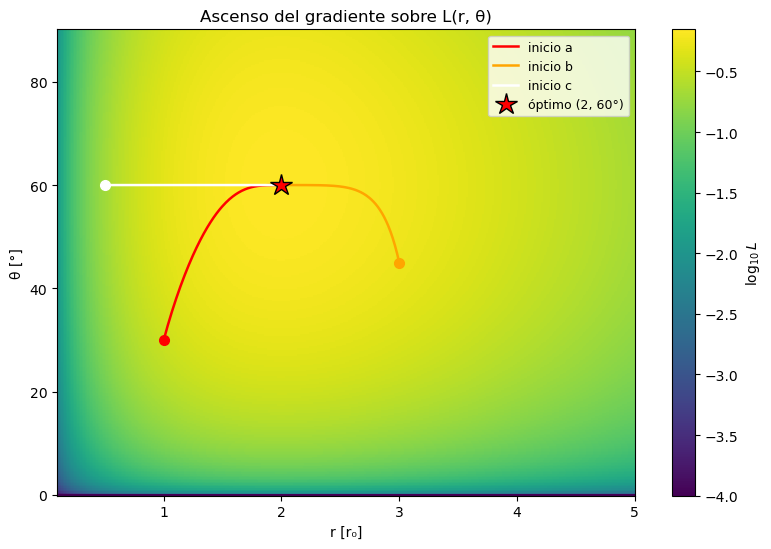

Interpretación: el gradiente 'sube' la colina de L hasta la cresta en θ = 60° y luego
avanza por ella hasta r = 2, donde ∇L = 0. Como L es unimodal en el dominio físico,
los tres inicios convergen al mismo máximo global.


In [2]:
# Mapa de L(r, θ) con las trayectorias del gradiente
rg = np.linspace(0.1, 5, 400)
thg = np.linspace(0, np.pi/2, 300)
RG, THG = np.meshgrid(rg, thg)
LG = L(RG, THG)

fig, ax = plt.subplots(figsize=(8, 5.6))
pc = ax.pcolormesh(RG, np.degrees(THG), np.log10(LG + 1e-4), shading='auto', cmap='viridis')
fig.colorbar(pc, label=r'$\log_{10} L$')
for etiqueta, camino, c in zip(resultados, resultados.values(), ['red', 'orange', 'white']):
    ax.plot(camino[:, 0], np.degrees(camino[:, 1]), '-', color=c, lw=1.8, label=f'inicio {etiqueta}')
    ax.plot(camino[0, 0], np.degrees(camino[0, 1]), 'o', color=c, ms=7)
ax.plot(2.0, 60.0, 'r*', ms=16, mec='k', label='óptimo (2, 60°)')
ax.set_xlabel('r [r₀]'); ax.set_ylabel('θ [°]')
ax.set_title('Ascenso del gradiente sobre L(r, θ)')
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

print("Interpretación: el gradiente 'sube' la colina de L hasta la cresta en θ = 60° y luego")
print("avanza por ella hasta r = 2, donde ∇L = 0. Como L es unimodal en el dominio físico,")
print("los tres inicios convergen al mismo máximo global.")